# [18.2] Sparse and Modular Training, KANs and Sparse Trees (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter18_intrinsic_interpretability/exercises/part2_sparse_modular_kans/18.2_Sparse_and_Modular_Training_KANs_and_Sparse_Trees_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter18_intrinsic_interpretability/exercises/part2_sparse_modular_kans/18.2_Sparse_and_Modular_Training_KANs_and_Sparse_Trees_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-12.png" width="350">

# Introduction

You want to explain a calculator: `output = first_input² + 0.5 × second_input`. A third input is irrelevant. A dense fitted model can nevertheless use that third input if the supplied training labels contain a nuisance pattern. Can a preference for short connections remove it? Could an edge function say “square” more clearly than a weight? And how many if-statements does a tree need to approximate the same smooth rule?

By the end of this notebook, you will have shown a concrete accuracy–interpretability tradeoff on the **same known additive regression task**: distance-weighted sparse fitting removes a designed nuisance at a shrinkage cost; a fitted piecewise-linear edge model exposes the square/linear decomposition; a leaf-penalized tree trades smooth accuracy for short rules. Exact oracles, irrelevant-feature controls and a linear baseline accompany the plots.

This study edition fits tiny ordinary CPU arrays. It teaches the mathematical components behind sparse modular training and KAN/sparse trees. The edge model is a one-layer, degree-one B-spline additive special case of a KAN, **not** the released multilayer pykan pipeline. The sparse linear fit illustrates distance-weighted L1 regularization, without BIMT neuron swapping. The tree is a transparent greedy baseline, without an OSDT global-optimality claim. Large/native model training and released-method qualification remain pending.

Prerequisites: matrix calculus, least squares, basic optimization (0.3), and the distinction between observational fit and intervention evidence from 18.1. No model downloads or GPU are needed.

## Content & Learning Objectives

### 1️⃣ Pay for connections
Implement a distance-weighted L1 objective and its proximal update. Distinguish sparse weights from actual modular behavior.
> ##### Learning Objectives
> - Compute connection costs, soft thresholding and a complete proximal fitting loop.
> - Compare unregularized, uniform L1 and locality-weighted fits on a known nuisance fixture.

### 2️⃣ Learn functions on edges
Build degree-one B-spline basis functions and fit an additive edge-function network.
> ##### Learning Objectives
> - Implement spline basis evaluation, a gauge-fixed additive design and edge decomposition.
> - Fit simple symbolic candidates to the learned edges and inspect off-knot error.

### 3️⃣ Build a sparse tree
Make the accuracy–rule-length tradeoff explicit with a leaf penalty.
> ##### Learning Objectives
> - Search all one-step splits, recursively fit a greedy tree, and print every rule.
> - Explain why greedy split search does not prove globally optimal sparse-tree fitting.

### 4️⃣ Compare the explanations
Evaluate all representations on the same public grid, with a wrong-feature baseline.
> ##### Learning Objectives
> - Read a controlled function-recovery and prediction dashboard.
> - Predict the failure caused by adding an interaction term to an additive task.

### ☆ Bonus
Gauge ambiguities, symbolic extrapolation, locality choices and optimal-tree solvers.

## Setup code

Use the existing course environment. No downloads, pretrained weights or accelerator are required. NumPy float64 makes every small matrix operation inspectable. Run from the repository or this chapter’s exercises directory. The setup discovers the chapter without relying on your current notebook filename.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
_root = next((p for p in _candidates if (p / "chapter18_intrinsic_interpretability" / "exercises").exists()), None)
if _root is not None:
    exercises_dir = _root / "chapter18_intrinsic_interpretability" / "exercises"
else:
    exercises_dir = next(p for p in _candidates if (p / "part2_sparse_modular_kans").exists())
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part2_sparse_modular_kans import tests as tests
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Pay for connections

> ##### Learning Objectives
>
> - Compare unregularized, uniform L1 and locality-weighted fits on a known nuisance fixture.

Brain-Inspired Modular Training (BIMT) places neurons in a geometric space and charges for the magnitude and length of their connections. We isolate that regularizer in a tiny linear multi-output fit. If $X$ is `[examples,input]` and $W$ is `[input,output]`, use
$$J(W)=\tfrac1{2n}\|XW-Y\|_F^2+\lambda\sum_{i,o}D_{io}|W_{io}|.$$
Here $D_{io}=1+|p_i-q_o|$ is a simple positive distance cost. We choose positions, rather than learning or swapping them; that is an explicit modeling assumption. Sparse weights are a representation property; separate ablations would be needed to establish task-level causal modules in a learned nonlinear network.

Our two desired outputs are centered square and half-linear components. We whiten three orthogonal features so the exact unregularized and thresholded solutions are easy to check. The training labels deliberately include a nuisance contribution from input three; the clean oracle does not. The “clean grid” is a **public teaching fixture**, not an untouched scientific TEST split. No hyperparameter is selected from it.

### Exercise - implement `mean_squared_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return elementwise mean squared error over all examples and outputs. This metric uses no 1/2 factor; the fitting objective above does.

In [ ]:
def mean_squared_error(predictions, targets):
    raise NotImplementedError()


tests.test_mean_squared_error(mean_squared_error)

<details><summary>Hint</summary>

Subtract, square, average all axes.

</details>

<details><summary>Help - why does this matter?</summary>

Always state the denominator: multi-output average MSE differs from the sum of output losses used in the gradient.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_mean_squared_error passed!`.
Predictions `[[1,3],[2,4]]` versus zeros give MSE `7.5`.

</details>


<details><summary>Solution</summary>

```python
def mean_squared_error(predictions, targets):
    return float(np.mean((np.asarray(predictions)-np.asarray(targets))**2))
```
</details>

### Exercise - implement `connection_cost`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return pairwise positive costs `[input,output]` for one-dimensional neuron positions. Equal positions still cost 1; distance should penalize long connections without making local connections free.

In [ ]:
def connection_cost(input_positions, output_positions):
    raise NotImplementedError()


tests.test_connection_cost(connection_cost)

<details><summary>Hint</summary>

Add a singleton output axis to input positions, and vice versa.

</details>

<details><summary>Help - why does this matter?</summary>

The distance prior chooses which connections are cheap. Bad geometry can penalize the true computation.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_connection_cost passed!`.
Input positions `[-1,1,0]`, output positions `[-1,1]` give rows `[1,3]`, `[3,1]`, `[2,2]`.

</details>


<details><summary>Solution</summary>

```python
def connection_cost(input_positions, output_positions):
    return 1.0 + np.abs(np.asarray(input_positions)[:,None] - np.asarray(output_positions)[None,:])
```
</details>

### Exercise - implement `soft_threshold`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the elementwise proximal operator of weighted L1: shrink each magnitude by its nonnegative threshold, clip at zero, and preserve sign. Broadcast thresholds.

In [ ]:
def soft_threshold(values, thresholds):
    raise NotImplementedError()


tests.test_soft_threshold(soft_threshold)

<details><summary>Hint</summary>

This is not hard thresholding: surviving weights must also shrink.

</details>

<details><summary>Help - why does this matter?</summary>

A zero is exact, which makes connection counts inspectable. Shrinkage of surviving useful edges is the price of the penalty.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_soft_threshold passed!`.
Values `[-2,-.1,0,.8]` with threshold `.2` become `[-1.8,0,0,.6]`.

</details>


<details><summary>Solution</summary>

```python
def soft_threshold(values, thresholds):
    return np.sign(values)*np.maximum(np.abs(values)-np.asarray(thresholds),0.0)
```
</details>

### Exercise - implement `proximal_fit`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit a zero-intercept multi-output matrix using a gradient step for the squared loss followed by weighted soft thresholding. Initialize zeros; keep the input arrays unchanged. This fixture uses a whitened design with spectral norm of `X.T@X/n` equal to one, so step size 0.5 is safely convergent.

In [ ]:
def proximal_fit(features, targets, costs, strength, steps=80, learning_rate=0.5):
    raise NotImplementedError()


tests.test_proximal_fit(proximal_fit)

<details><summary>Hint</summary>

Apply the penalty after the data gradient, and scale its threshold by the same learning rate.

</details>

<details><summary>Help - why does this matter?</summary>

The method is genuinely fitted here, rather than displaying a planted sparse matrix. That does not establish that the same regularizer produces semantic modules on a larger neural task.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_proximal_fit passed!`.
On an identity-covariance design the optimum is `soft_threshold(X.T@Y/n, strength*costs)`. The independent check uses this closed form.

</details>


<details><summary>Solution</summary>

```python
def proximal_fit(features, targets, costs, strength, steps=80, learning_rate=0.5):
    x=np.asarray(features,dtype=float)
    y=np.asarray(targets,dtype=float)
    w=np.zeros((x.shape[1],y.shape[1]))
    for _ in range(steps):
        gradient=x.T@(x@w-y)/len(x)
        w=soft_threshold(w-learning_rate*gradient,learning_rate*strength*np.asarray(costs))
    return w
```
</details>

### Exercise - implement `off_module_fraction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the fraction of total absolute connection mass outside a supplied boolean module mask. Return zero for an all-zero network. This is a chosen-layout diagnostic, not Newman graph modularity.

In [ ]:
def off_module_fraction(weights, allowed):
    raise NotImplementedError()


tests.test_off_module_fraction(off_module_fraction)

<details><summary>Hint</summary>

Use absolute values so opposite signs do not cancel.

</details>

<details><summary>Help - why does this matter?</summary>

Calling a weight pattern modular requires naming the proposed modules. This score cannot certify that the modules correspond to meaningful causal variables.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_off_module_fraction passed!`.
For weights `[[2,1],[0,1]]` and a diagonal mask the off-module fraction is `1/4`.

</details>


<details><summary>Solution</summary>

```python
def off_module_fraction(weights, allowed):
    magnitude=np.abs(weights)
    total=magnitude.sum()
    return float(magnitude[~np.asarray(allowed,dtype=bool)].sum()/total) if total else 0.0
```
</details>


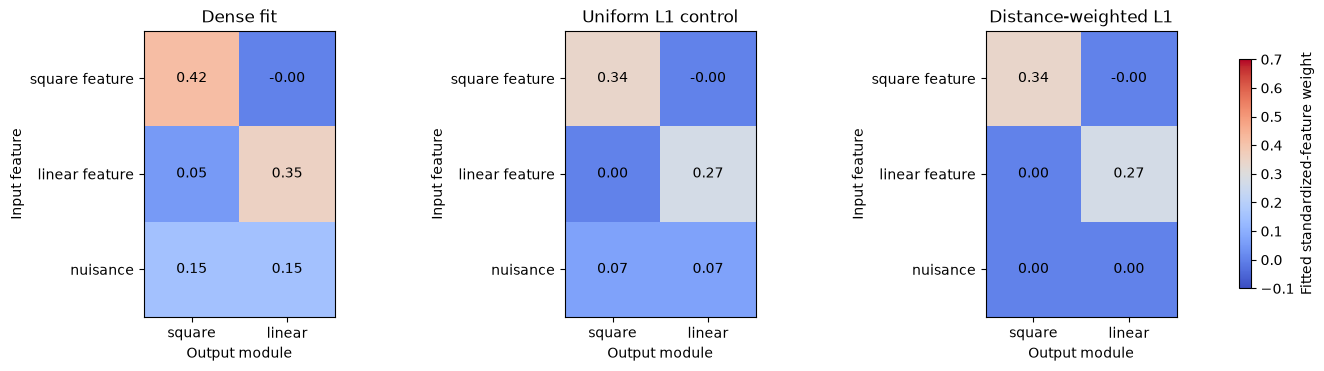

In [ ]:
from itertools import product
knots = np.linspace(-1.,1.,5)
# Public construction grid: 5 x 5 x 2 = 50 points, with no sampling or data selection.
train_x = np.array(list(product(knots,knots,[-1.,1.])))
raw_features=np.column_stack([train_x[:,0]**2-.5,train_x[:,1],train_x[:,2]])
feature_scale=np.sqrt(np.mean(raw_features**2,axis=0))
X=raw_features/feature_scale
assert np.allclose(X.T@X/len(X),np.eye(3))
clean_components=np.column_stack([raw_features[:,0],.5*raw_features[:,1]])
# A deliberately supplied, recoverable perturbation, not a natural dataset.
training_components=clean_components + np.column_stack([.05*X[:,1]+.15*X[:,2],.15*X[:,2]])
costs=connection_cost([-1.,1.,0.],[-1.,1.])
allowed=np.array([[True,False],[False,True],[False,False]])
dense_weights=proximal_fit(X,training_components,np.ones((3,2)),0.)
l1_weights=proximal_fit(X,training_components,np.ones((3,2)),.08)
local_weights=proximal_fit(X,training_components,costs,.08)
for name,w in [('dense',dense_weights),('uniform L1',l1_weights),('distance L1',local_weights)]:
    print(name,'clean component MSE / off-module mass / nonzero edges:',round(mean_squared_error(X@w,clean_components),6),round(off_module_fraction(w,allowed),4),int(np.sum(np.abs(w)>1e-8)))
fig,axes=plt.subplots(1,3,figsize=(14,3.6),layout="constrained")
for ax,w,name in zip(axes,[dense_weights,l1_weights,local_weights],['Dense fit','Uniform L1 control','Distance-weighted L1']):
    im=ax.imshow(w,vmin=-.1,vmax=.7,cmap='coolwarm')
    ax.set(xticks=[0,1],xticklabels=['square','linear'],yticks=[0,1,2],yticklabels=['square feature','linear feature','nuisance'],xlabel='Output module',ylabel='Input feature',title=name)
    for i in range(3):
        for j in range(2): ax.text(j,i,f'{w[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=list(axes),label='Fitted standardized-feature weight',shrink=.8)
plt.show()

<details><summary>Help - what was actually learned?</summary>

All three matrices were fitted to exactly the same perturbed label array. Uniform L1 removes the .05 cross-link but retains part of each .15 nuisance link. The distance prior makes nuisance links twice as costly and removes both at strength .08. It also shrinks the real local links, so its clean error is nonzero. This is a controlled regularization mechanism with known truth, not discovery of a previously unknown scientific module. The uniform penalty is the control separating sparsity from the additional locality assumption.

</details>

<details><summary>Expected output from the fitted fixture</summary>

<pre style="font-size: 13px">
dense clean MSE 0.023750; off-module mass 0.3120; 5 nonzero edges
uniform L1 clean MSE 0.011300; off-module mass 0.1862; 4 nonzero edges
distance L1 clean MSE 0.006400; off-module mass 0.0000; 2 nonzero edges
</pre>

The count uses absolute magnitude greater than `1e-8`; off-module mass uses absolute weights.

</details>

## Summary of 1️⃣
You implemented the whole fitting algorithm and a module diagnostic. A visually sparse network can still be biased, and a distance prior can help only if its geometry fits the task.

# 2️⃣ Learn functions on edges

> ##### Learning Objectives
>
> - Fit simple symbolic candidates to the learned edges and inspect off-knot error.

A standard linear layer sums weighted inputs. A KAN layer instead sums learned univariate edge functions, $z_o=\sum_i\phi_{oi}(x_i)$. With one scalar output and one layer, this is an additive model. We will fit $\hat y=b+\phi_0(x_0)+\phi_1(x_1)$ using degree-one B-splines, also called hat functions. These are a real spline parameterization, not fixed arbitrary activations or a disguised MLP.

At knots $t_0<\cdots<t_{K-1}$, hat $B_k(x)$ is one at $t_k$, zero at the other knots, and linear between adjacent knots. The hats form a partition of unity inside the knot interval. We intentionally reject extrapolation instead of silently choosing an outside-domain rule.

There is a gauge ambiguity: a constant can move between edges without changing the sum. Fix $\phi_i(0)=0$ and retain one explicit intercept. Form $\tilde B_k(x)=B_k(x)-B_k(0)$, then remove the zero knot’s basis column because the centered basis columns sum to zero. The design has shape `[batch, 1 + inputs*(knots-1)]`. A recovered edge curve now has a consistent origin.

### Exercise - implement `hat_basis`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Evaluate piecewise-linear hat functions on arbitrary-shaped values, returning `values.shape + (K,)`. Include both endpoints correctly, allow nonuniform knots, and reject values outside the interval or repeated knots.

In [ ]:
def hat_basis(values, knots):
    raise NotImplementedError()


tests.test_hat_basis(hat_basis)

<details><summary>Hint</summary>

Handle each hat’s left and right interval. Use one strict inequality at its peak to avoid counting it twice.

</details>

<details><summary>Help - why does this matter?</summary>

This is the actual function basis learned on each edge. Plotting a learned curve is only meaningful if the basis evaluates correctly between knots.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_hat_basis passed!`.
For knots `[-1,0,1]` and values `[-1,-.5,0,.5,1]`, the rows are `[1,0,0]`, `[.5,.5,0]`, `[0,1,0]`, `[0,.5,.5]`, `[0,0,1]`.

</details>


<details><summary>Solution</summary>

```python
def hat_basis(values, knots):
    values=np.asarray(values,dtype=float)
    knots=np.asarray(knots,dtype=float)
    if len(knots)<2 or np.any(np.diff(knots)<=0):
        raise ValueError("knots must be strictly increasing")
    if np.any(values<knots[0]) or np.any(values>knots[-1]):
        raise ValueError("outside spline domain")
    basis=np.zeros(values.shape+(len(knots),))
    for k in range(len(knots)):
        if k>0:
            left=(values>=knots[k-1])&(values<=knots[k])
            basis[...,k]+=np.where(left,(values-knots[k-1])/(knots[k]-knots[k-1]),0.)
        if k<len(knots)-1:
            right=(values>knots[k])&(values<=knots[k+1])
            basis[...,k]+=np.where(right,(knots[k+1]-values)/(knots[k+1]-knots[k]),0.)
    # The first knot has no left interval.
    basis[...,0]=np.where(values==knots[0],1.,basis[...,0])
    return basis
```
</details>

### Exercise - implement `additive_design`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Build the gauge-fixed additive design for inputs `[batch,inputs]`. Subtract the basis at zero, remove the unique zero-knot basis column per feature, flatten in input-major order and prepend an intercept column.

In [ ]:
def additive_design(inputs, knots):
    raise NotImplementedError()


tests.test_additive_design(additive_design)

<details><summary>Hint</summary>

Keep the feature axis separate until you have removed the anchor column.

</details>

<details><summary>Help - why does this matter?</summary>

Without a fixed gauge, two equally accurate fits can display different constant offsets on their edge plots, creating misleading explanations.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_additive_design passed!`.
Two inputs with five knots produce nine design columns. At the all-zero input, only the intercept column is nonzero.

</details>


<details><summary>Solution</summary>

```python
def additive_design(inputs, knots):
    inputs=np.asarray(inputs,dtype=float)
    knots=np.asarray(knots,dtype=float)
    anchor=np.flatnonzero(np.isclose(knots,0.))
    if len(anchor)!=1:
        raise ValueError("exactly one zero anchor knot is required")
    centered=hat_basis(inputs,knots)-hat_basis(np.array(0.),knots)
    reduced=np.delete(centered,int(anchor[0]),axis=-1)
    return np.column_stack([np.ones(len(inputs)),reduced.reshape(len(inputs),-1)])
```
</details>

### Exercise - implement `fit_additive_spline`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit the visible additive edge model by least squares. Return the intercept followed by the gauge-fixed edge coefficients. No optimizer or nonlinear search is necessary for this fixed-basis teaching instance.

In [ ]:
def fit_additive_spline(inputs, targets, knots):
    raise NotImplementedError()


tests.test_fit_additive_spline(fit_additive_spline)

<details><summary>Hint</summary>

Use the preceding design matrix directly.

</details>

<details><summary>Help - why does this matter?</summary>

Learning the edge coefficients is a real fit. It remains much simpler than learning multiple layers, grids and base-function residuals in the released KAN implementation.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_fit_additive_spline passed!`.
A target equal to `x0 + 2*x1` is recovered exactly throughout the knot interval.

</details>


<details><summary>Solution</summary>

```python
def fit_additive_spline(inputs, targets, knots):
    return np.linalg.lstsq(additive_design(inputs,knots),np.asarray(targets),rcond=None)[0]
```
</details>

### Exercise - implement `edge_values`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the separate fitted edge contributions `[batch,inputs]`, excluding the shared intercept. Their sum plus `coefficients[0]` must reproduce the full additive prediction.

In [ ]:
def edge_values(inputs, coefficients, knots):
    raise NotImplementedError()


tests.test_edge_values(edge_values)

<details><summary>Hint</summary>

Reshape the reduced basis and coefficients to explicit input/edge-coefficient axes.

</details>

<details><summary>Help - why does this matter?</summary>

The sum identity is the explanation contract: the plotted edge values must actually add up to the prediction.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_edge_values passed!`.
For a fitted `x0+2*x1` rule, input `[.25,-.5]` has edge contributions `[.25,-1]`.

</details>


<details><summary>Solution</summary>

```python
def edge_values(inputs, coefficients, knots):
    inputs=np.asarray(inputs,dtype=float)
    design=additive_design(inputs,knots)[:,1:]
    width=len(knots)-1
    return np.sum(design.reshape(len(inputs),inputs.shape[1],width)*np.asarray(coefficients)[1:].reshape(inputs.shape[1],width),axis=-1)
```
</details>

### Exercise - implement `symbolic_affine_fit`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit `offset + scale * candidate(x)` to sampled learned edge values. Return `[offset,scale]` and MSE. Candidate functions are supplied explicitly; this function does not search an unbounded formula language.

In [ ]:
def symbolic_affine_fit(coordinate, edge, candidate):
    raise NotImplementedError()


tests.test_symbolic_affine_fit(symbolic_affine_fit)

<details><summary>Hint</summary>

A candidate turns symbolic fitting into a two-column linear regression.

</details>

<details><summary>Help - why does this matter?</summary>

A formula matching knot samples need not equal a piecewise-linear spline between knots. We will check both against the known rule rather than treating a symbolic name as proof.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_symbolic_affine_fit passed!`.
Candidate `square` fitted to edge values `3 + 2*x²` returns `[3,2]` and zero residual to numerical precision.

</details>


<details><summary>Solution</summary>

```python
def symbolic_affine_fit(coordinate, edge, candidate):
    z=np.asarray(candidate(np.asarray(coordinate)),dtype=float)
    design=np.column_stack([np.ones(len(z)),z])
    params=np.linalg.lstsq(design,np.asarray(edge),rcond=None)[0]
    residual=mean_squared_error(design@params,edge)
    return params,residual
```
</details>

In [ ]:
spline_coefficients=fit_additive_spline(train_x[:,:2],train_x[:,0]**2+.5*train_x[:,1],knots)
edge_grid=np.column_stack([knots,np.zeros(len(knots))])
square_edge=edge_values(edge_grid,spline_coefficients,knots)[:,0]
line_grid=np.column_stack([np.zeros(len(knots)),knots])
linear_edge=edge_values(line_grid,spline_coefficients,knots)[:,1]
square_params,square_residual=symbolic_affine_fit(knots,square_edge,np.square)
linear_params,linear_residual=symbolic_affine_fit(knots,linear_edge,lambda x:x)
wrong_params,wrong_residual=symbolic_affine_fit(knots,square_edge,lambda x:x)
print('Recovered square offset/scale, knot MSE:',square_params,round(square_residual,12))
print('Recovered linear offset/scale, knot MSE:',linear_params,round(linear_residual,12))
print('Wrong linear explanation of square, knot MSE:',round(wrong_residual,6))
print('Off-knot x=.25: spline square / symbolic square / oracle:',edge_values(np.array([[.25,0.]]),spline_coefficients,knots)[0,0],square_params[0]+square_params[1]*.25**2,.25**2)

<details><summary>Expected output</summary>

At the five knots, the square edge fits `0 + 1*x²` and the linear edge fits `0 + 0.5*x`, to floating precision. A linear symbolic candidate for the square has knot MSE `0.175`. At `x=0.25`, the piecewise-linear square edge gives `0.125`, while the symbolic expression and oracle give `0.0625`. The symbolic approximation is better for this known generating rule, but it is **not** an algebraic identity of the learned spline.

</details>

## Summary of 2️⃣
You fitted edge functions, fixed their additive gauge and recovered simple candidate formulas. You also found an honest mismatch between fitting symbolic names at knots and explaining the function everywhere.

# 3️⃣ Build a sparse tree

> ##### Learning Objectives
>
> - Explain why greedy split search does not prove globally optimal sparse-tree fitting.

A regression tree gives an alternative explanation: follow comparisons to reach a constant-valued leaf. Its training criterion is $\mathrm{SSE}/n+\lambda L$, where $L$ is the number of leaves. Splitting a leaf adds one leaf, so a proposed split is worthwhile when its reduction in SSE divided by the **original root sample count** exceeds $\lambda$.

We search all feature/threshold pairs for the best immediate reduction, then recurse. Thresholds are midpoints between distinct observed values. Ties break by feature index, then increasing threshold. This is **greedy CART-like fitting**, not global optimization of a sparse tree: a temporarily poor split might enable valuable deeper structure. The OSDT papers motivate sparse-tree objectives and explicitly address global optimality; our baseline does not implement their branch-and-bound solver.

Leaves are dictionaries `{'value': mean_label}`. Split nodes contain `feature`, `threshold`, `left`, `right`; the left branch includes equality. The same schema drives both predictions and printed explanations.

### Exercise - implement `best_split`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Enumerate all legal one-step splits and return `(feature,threshold,SSE_reduction)`. If no strictly positive gain exists, return `(None,None,0)`. Do not split constant columns or create empty children.

In [ ]:
def best_split(inputs, targets):
    raise NotImplementedError()


tests.test_best_split(best_split)

<details><summary>Hint</summary>

Compute within-child sums of squared residuals around each child mean.

</details>

<details><summary>Help - why does this matter?</summary>

A threshold is an explicit explanatory claim. Exhaustive one-step checking avoids hiding a library tree behind a plot, but it remains only one-step optimal.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_best_split passed!`.
Inputs `[0,1,2,3]` with labels `[0,0,2,2]` choose threshold `1.5`, reducing SSE by 4.

</details>


<details><summary>Solution</summary>

```python
def best_split(inputs, targets):
    x=np.asarray(inputs);y=np.asarray(targets,dtype=float)
    parent=np.sum((y-y.mean())**2)
    best=(None,None,0.0)
    for feature in range(x.shape[1]):
        unique=np.unique(x[:,feature])
        for threshold in (unique[:-1]+unique[1:])/2:
            left=x[:,feature]<=threshold
            sse=np.sum((y[left]-y[left].mean())**2)+np.sum((y[~left]-y[~left].mean())**2)
            gain=float(parent-sse)
            if gain>best[2]+1e-12:
                best=(feature,float(threshold),gain)
    return best
```
</details>

### Exercise - implement `fit_sparse_tree`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Recursively choose the best immediate split. Accept it only when global mean-SSE reduction exceeds the extra-leaf penalty. Keep the original `root_count` through recursion and stop at depth zero. A root-only tree has one leaf.

In [ ]:
def fit_sparse_tree(inputs, targets, penalty=0.01, max_depth=4, root_count=None):
    raise NotImplementedError()


tests.test_fit_sparse_tree(fit_sparse_tree)

<details><summary>Hint</summary>

The leaf value is always the local label mean; the penalty denominator never becomes the child count.

</details>

<details><summary>Help - why does this matter?</summary>

Using the child count would silently change the objective with depth and favor unnecessary deep branches.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_fit_sparse_tree passed!`.
For labels `[0,0,2,2]` on inputs `[0,1,2,3]`, penalty below 1 permits the exact two-leaf tree; penalty 1 or above retains one leaf because ties favor simplicity.

</details>


<details><summary>Solution</summary>

```python
def fit_sparse_tree(inputs, targets, penalty=0.01, max_depth=4, root_count=None):
    x=np.asarray(inputs);y=np.asarray(targets,dtype=float)
    root_count=len(y) if root_count is None else root_count
    leaf={"value":float(y.mean())}
    if max_depth==0 or len(y)<2:
        return leaf
    feature,threshold,gain=best_split(x,y)
    if feature is None or gain/root_count<=penalty:
        return leaf
    left=x[:,feature]<=threshold
    return {"feature":feature,"threshold":threshold,
            "left":fit_sparse_tree(x[left],y[left],penalty,max_depth-1,root_count),
            "right":fit_sparse_tree(x[~left],y[~left],penalty,max_depth-1,root_count)}
```
</details>

### Exercise - implement `predict_tree`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Evaluate the exact dictionary tree, preserving input order. Use the left child for values equal to a threshold. Empty batches should return empty arrays.

In [ ]:
def predict_tree(tree, inputs):
    raise NotImplementedError()


tests.test_predict_tree(predict_tree)

<details><summary>Hint</summary>

Partition a batch with a boolean mask, recurse, then fill the original positions.

</details>

<details><summary>Help - why does this matter?</summary>

Predictions and explanations must refer to the same thresholds. Off-by-one branch semantics can invalidate an otherwise plausible rule list.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_predict_tree passed!`.
A threshold-0 leaf pair with values -1 and 2 maps inputs `[-.1,0,.1]` to `[-1,-1,2]`.

</details>


<details><summary>Solution</summary>

```python
def predict_tree(tree, inputs):
    x=np.asarray(inputs)
    if "value" in tree:
        return np.full(len(x),tree["value"])
    left=x[:,tree["feature"]]<=tree["threshold"]
    pred=np.empty(len(x))
    pred[left]=predict_tree(tree["left"],x[left])
    pred[~left]=predict_tree(tree["right"],x[~left])
    return pred
```
</details>

### Exercise - implement `tree_leaves`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Count terminal values recursively. Count leaves, not decision nodes, because the objective above charges for terminal rules.

In [ ]:
def tree_leaves(tree):
    raise NotImplementedError()


tests.test_tree_leaves(tree_leaves)

<details><summary>Hint</summary>

A leaf has one terminal rule; a split combines its two children.

</details>

<details><summary>Help - why does this matter?</summary>

The complexity axis must correspond to the penalty actually fitted, rather than a convenient but different count.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_tree_leaves passed!`.
A stump with two terminal predictions has two leaves and one decision node.

</details>


<details><summary>Solution</summary>

```python
def tree_leaves(tree):
    return 1 if "value" in tree else tree_leaves(tree["left"])+tree_leaves(tree["right"])
```
</details>

### Exercise - implement `tree_paths`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a list of `(rule_string,leaf_value)` pairs in left-to-right order. Prefix deeper conditions with `and`. Do not silently drop any branch.

In [ ]:
def tree_paths(tree, prefix=""):
    raise NotImplementedError()


tests.test_tree_paths(tree_paths)

<details><summary>Hint</summary>

Use the same comparison direction as `predict_tree`.

</details>

<details><summary>Help - why does this matter?</summary>

A small leaf count is interpretable only if a person can actually read the rules. A rule list gives a concrete check on that claim.

</details>

<details><summary>Expected output</summary>

The immediate semantic check prints `All tests in test_tree_paths passed!`.
The threshold-0 stump produces rules `x0 <= 0` and `x0 > 0`.

</details>


<details><summary>Solution</summary>

```python
def tree_paths(tree, prefix=""):
    if "value" in tree:
        return [(prefix or "always",tree["value"])]
    name=f'x{tree["feature"]}'
    threshold=tree["threshold"]
    left=(prefix+" and " if prefix else "")+f'{name} <= {threshold:g}'
    right=(prefix+" and " if prefix else "")+f'{name} > {threshold:g}'
    return tree_paths(tree["left"],left)+tree_paths(tree["right"],right)
```
</details>

In [ ]:
train_y=train_x[:,0]**2+.5*train_x[:,1]
small_tree=fit_sparse_tree(train_x,train_y,penalty=.03,max_depth=4)
large_tree=fit_sparse_tree(train_x,train_y,penalty=0.,max_depth=5)
for name,tree in [('penalized',small_tree),('unpenalized depth-5',large_tree)]:
    print(name,'leaves / construction-grid MSE:',tree_leaves(tree),round(mean_squared_error(predict_tree(tree,train_x),train_y),6))
print('Penalized model rules:')
for condition,value in tree_paths(small_tree):
    print(f'  IF {condition} THEN {value:.4f}')

<details><summary>Help - why might a tree need many leaves?</summary>

The generating function is smooth. Each tree leaf is constant on an axis-aligned region, so matching a square and a slope requires multiple regions. The spline spends coefficients on continuously varying edges; the tree spends leaves on separate regions. Their parameter counts are different currencies, so we will label both rather than rank them with a single unqualified “interpretability” score.

The nuisance feature never improves a split on this exact balanced grid. If your tree repeatedly splits `x2`, check feature indexing, label construction and tie handling before explaining it as discovery.

</details>

<details><summary>Expected output from the tree fixture</summary>

The penalized tree has 4 leaves and construction-grid MSE `0.106250`. Its first rule is `x1 <= -0.25`, predicting `0.1250`. The larger depth-five tree has 18 leaves and construction MSE `0.007083`. It still has nonzero error: “unpenalized” does not mean unlimited depth or a globally optimal fit.

</details>

## Summary of 3️⃣
You built a full inspectable regression tree and its rule printer. The penalty limits immediate split gains; it is not a certificate of a globally optimal sparse tree.

# 4️⃣ Compare the explanations

> ##### Learning Objectives
>
> - Predict the failure caused by adding an interaction term to an additive task.

### Freeze the comparison before plotting

The construction grid uses five knot values per relevant input and both nuisance signs. The public interpolation grid uses nine evenly spaced values per relevant input and both nuisance signs (162 rows). We do not fit or select models on the interpolation grid. Every reported MSE uses the known analytic target, not the perturbed training labels from part 1.

The following linear baseline is fitted on `[1,x0,x1,x2]`. It cannot represent a square. The irrelevant-input-only spline is a negative control; it receives only x2. The fitted additive spline and both trees use the same clean construction labels. This comparison isolates **function class and complexity**. Part 1’s perturbed-label regularization demo has a different label contract and is not inserted as a competing nonlinear model.

Before plotting, predict which model has zero construction error yet nonzero interpolation error. Will a symbolic square recovered at the knots reproduce the learned spline between the knots?


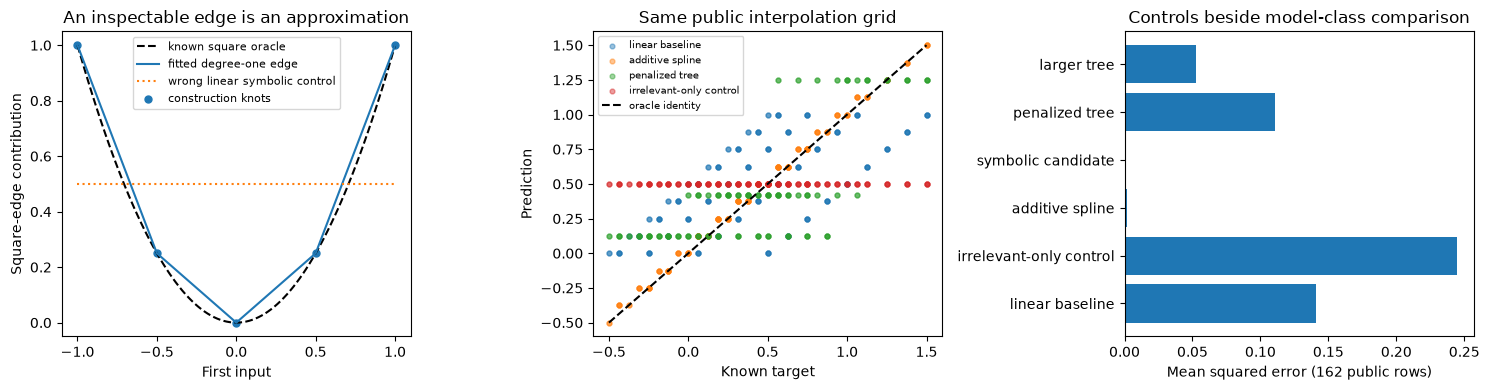

In [ ]:
eval_axis=np.linspace(-1.,1.,9)
eval_x=np.array(list(product(eval_axis,eval_axis,[-1.,1.])))
eval_y=eval_x[:,0]**2+.5*eval_x[:,1]
linear_w=np.linalg.lstsq(np.column_stack([np.ones(len(train_x)),train_x]),train_y,rcond=None)[0]
linear_pred=np.column_stack([np.ones(len(eval_x)),eval_x])@linear_w
spline_pred=additive_design(eval_x[:,:2],knots)@spline_coefficients
wrong_feature_w=fit_additive_spline(train_x[:,2:3],train_y,knots)
wrong_feature_pred=additive_design(eval_x[:,2:3],knots)@wrong_feature_w
symbolic_pred=square_params[0]+square_params[1]*eval_x[:,0]**2+linear_params[0]+linear_params[1]*eval_x[:,1]+spline_coefficients[0]
model_predictions={'linear baseline':linear_pred,'irrelevant-only control':wrong_feature_pred,'additive spline':spline_pred,'symbolic candidate':symbolic_pred,'penalized tree':predict_tree(small_tree,eval_x),'larger tree':predict_tree(large_tree,eval_x)}
for name,prediction in model_predictions.items():
    print(f'{name:25s} interpolation MSE {mean_squared_error(prediction,eval_y):.6f}')
fig,axes=plt.subplots(1,3,figsize=(15,4))
curve=np.linspace(-1.,1.,101)
curve_x=np.column_stack([curve,np.zeros_like(curve)])
learned_edge=edge_values(curve_x,spline_coefficients,knots)[:,0]
axes[0].plot(curve,curve**2,'k--',label='known square oracle')
axes[0].plot(curve,learned_edge,label='fitted degree-one edge')
axes[0].plot(curve,wrong_params[0]+wrong_params[1]*curve,':',label='wrong linear symbolic control')
axes[0].scatter(knots,square_edge,color='C0',s=25,label='construction knots')
axes[0].set(xlabel='First input',ylabel='Square-edge contribution',title='An inspectable edge is an approximation')
axes[0].legend(fontsize=8)
for name in ['linear baseline','additive spline','penalized tree','irrelevant-only control']:
    axes[1].scatter(eval_y,model_predictions[name],s=12,alpha=.45,label=name)
axes[1].plot([-.5,1.5],[-.5,1.5],'k--',label='oracle identity')
axes[1].set(xlabel='Known target',ylabel='Prediction',title='Same public interpolation grid')
axes[1].legend(fontsize=7)
names=list(model_predictions)
errors=[mean_squared_error(model_predictions[name],eval_y) for name in names]
axes[2].barh(names,errors)
axes[2].set(xlabel='Mean squared error (162 public rows)',title='Controls beside model-class comparison')
fig.tight_layout();plt.show()
print('Complexity currencies: linear',len(linear_w),'coefficients; spline',len(spline_coefficients),'coefficients;',tree_leaves(small_tree),'and',tree_leaves(large_tree),'tree leaves; symbolic two candidate forms plus fitted scales/offsets.')

<details><summary>Expected output from the frozen public interpolation grid</summary>

<pre style="font-size: 13px">
linear baseline          MSE 0.140625
irrelevant-only control  MSE 0.244792
additive spline          MSE 0.001736
symbolic candidate       MSE 0.000000
penalized tree           MSE 0.111047
larger tree              MSE 0.052662
</pre>

The spline has nine fitted coefficients. The baseline has four coefficients. Trees have four and eighteen leaves; these are different complexity currencies.

</details>

## Interpreting the result

<details><summary>Help - what should this figure convince me of?</summary>

The fitted edge follows the square at knots and uses straight lines between them. The dashed oracle bows below the segments; the difference is real approximation error. The symbolic candidate recovers the known generating formula here, but its exactness follows from the supplied oracle and candidate family, not from naming a plot “symbolic regression.” The linear baseline misses the square; the irrelevant-only control misses both relevant variables. A larger tree can fit more construction points, but still predicts constants between its thresholds.

The comparison does not establish that a KAN is generally more interpretable or accurate than a neural network. It establishes a concrete accounting of what these particular representations expose and where their errors arise. Ask whether the explanation object is a weight, an edge function or a decision rule before comparing its complexity.

</details>

## Try it yourself

The original function is additive. Change it to include `interaction * x0*x1` with coefficient 1. Before running, predict why even an infinitely fine one-layer additive spline cannot represent the new term. Its mixed finite difference is zero, while the target’s mixed finite difference is not. The known polynomial oracle is a baseline with the interaction explicitly included.


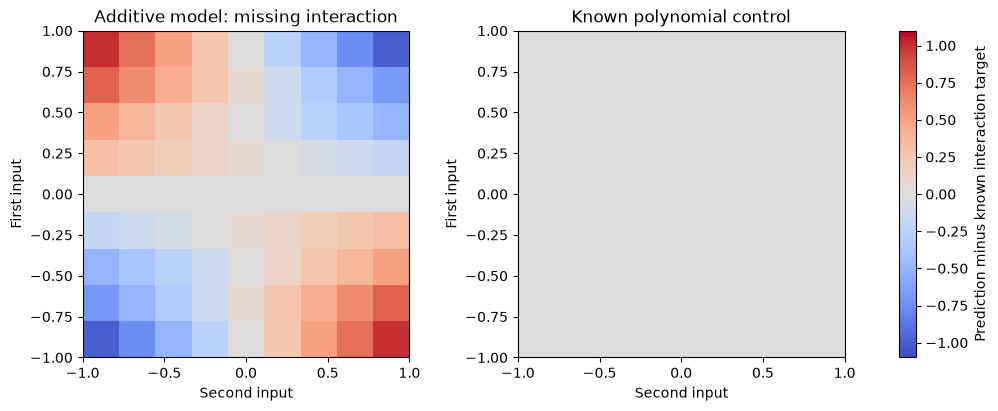

In [ ]:
interaction=1.0  # Change the task, not merely the random seed.
train_changed=train_y+interaction*train_x[:,0]*train_x[:,1]
eval_changed=eval_y+interaction*eval_x[:,0]*eval_x[:,1]
changed_coefficients=fit_additive_spline(train_x[:,:2],train_changed,knots)
changed_pred=additive_design(eval_x[:,:2],knots)@changed_coefficients
changed_tree=fit_sparse_tree(train_x,train_changed,penalty=.01,max_depth=5)
polynomial_oracle=eval_x[:,0]**2+.5*eval_x[:,1]+interaction*eval_x[:,0]*eval_x[:,1]
print('Changed-task MSE: additive / tree / known polynomial',mean_squared_error(changed_pred,eval_changed),mean_squared_error(predict_tree(changed_tree,eval_x),eval_changed),mean_squared_error(polynomial_oracle,eval_changed))
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for ax,pred,title in zip(axes,[changed_pred,polynomial_oracle],['Additive model: missing interaction','Known polynomial control']):
    residual=(pred-eval_changed).reshape(9,9,2).mean(-1)
    im=ax.imshow(residual,origin='lower',extent=[-1,1,-1,1],vmin=-1.1,vmax=1.1,cmap='coolwarm')
    ax.set(xlabel='Second input',ylabel='First input',title=title)
fig.colorbar(im,ax=list(axes),label='Prediction minus known interaction target')
plt.show()

<details><summary>Help - an anomaly worth investigating</summary>

Why are the additive edge coefficients essentially unchanged after adding the interaction? On the balanced construction grid, `x0*x1` has zero mean conditional on either single input, so it is orthogonal to every additive basis column. The residual heatmap therefore retains the interaction’s sign pattern. A deeper KAN can compose univariate functions through hidden sums and need not share the one-layer limitation. Do not generalize this failure to every KAN.

</details>

<details><summary>Expected output for interaction coefficient 1</summary>

The additive model’s public-grid MSE is `0.175347`; the greedy changed-task tree’s is `0.084855`; the known polynomial control is exactly zero. The additive residual heatmap changes sign in opposite quadrants, while the oracle-control panel stays zero on the same color scale.

</details>

## Summary of 4️⃣
You compared visible explanatory objects on the same regression task, then changed the task in a way that violates one model class’s structural assumption. The resulting residual is more informative than a generic accuracy ranking.

## Limitations

The regularizer demo uses an orthogonal, engineered finite feature design and a known nuisance perturbation. It does not establish nonlinear BIMT performance, optimize neuron positions or include neuron swaps. The KAN component uses one additive layer, a fixed degree-one grid and least-squares coefficients; it omits the released pykan cubic-spline/SILU parameterization, multilayer training, grid extension, pruning and full symbolic replacement workflow. Its symbolic fit checks two deliberately appropriate candidates and one wrong candidate, not open-ended scientific equation discovery. The regression tree is greedy and depth-bounded; no OSDT/GOSDT optimality certificate is claimed. Construction and interpolation grids are public teaching fixtures. Full native/released-method comparison, independent experimental evaluation and human learner acceptance remain pending.

# ☆ Bonus

Try shifting a constant from one spline edge to the other before gauge fixing. Does the sum change? Put both input modules at the wrong geometric positions in part 1: which useful edge becomes expensive? Construct a target where the best immediate tree split has zero gain but a two-step tree is perfect (XOR is a useful clue). Would the greedy fitting rule find it? Would an optimal sparse-tree solver necessarily choose it at every leaf penalty?

## Further Reading

- [Liu, Gan and Tegmark, Seeing is Believing: Brain-Inspired Modular Training](https://arxiv.org/abs/2305.08746): geometric connection penalties and neuron rearrangement; the latter is absent from this teaching component.
- [Liu et al., KAN: Kolmogorov–Arnold Networks](https://arxiv.org/abs/2404.19756): learned univariate edge functions, splines and symbolic interpretability; the existence theorem is not an optimization or generalization guarantee.
- [Official pykan implementation](https://github.com/KindXiaoming/pykan): released multilayer spline training and symbolic tools; consult its pinned revision before making parity claims.
- [Hu, Rudin and Seltzer, Optimal Sparse Decision Trees](https://proceedings.neurips.cc/paper/2019/hash/ac52c626afc10d4075708ac4c778ddfc-Abstract.html): sparse-tree objectives and global optimization for binary variables.
- [Lin et al., Generalized and Scalable Optimal Sparse Decision Trees](https://proceedings.mlr.press/v119/lin20g.html): generalized objectives and continuous variables; substantially beyond our greedy baseline.